## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [5]:
import pickle

with open('/content/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Helen Ayalew

**Date:** 10/19/2026

In [6]:
# Your Phase 1 solution to the problem goes here.

# All imports needed
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

with open('/content/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

# Reading the file contents
df = pd.read_parquet('/content/Phishing_clean.parquet')
df

,Email Type,new,date,get,please,enron,like,2002,would,one,...,ï¿½ï¿½,safety,yap,ypil,maintain,procedures,tip,elizabeth,leadership,italian
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18629,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
18630,0,0,0,0,1,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
18631,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
18632,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [24]:
# Displaying the contents of token_count
token_count_df = pd.DataFrame(token_count.items(), columns=['Token', 'Frequency'])
token_count_df

,Token,Frequency
0,1100,6
1,disc,30
2,uniformitarianism,4
3,1086,2
4,sex,150
...,...,...
48686,"feet,",1
48687,housewifes,1
48688,dorn,1
48689,clippings,1


In [21]:
# Displaying the contents of token_freq in a table
token_freq_df = pd.DataFrame(token_freq, columns=['Token', 'Frequency'])
token_freq_df

,Token,Frequency
0,new,1365
1,date,1202
2,get,1052
3,please,1022
4,enron,927
...,...,...
48686,truck[1].,1
48687,"feet,",1
48688,housewifes,1
48689,dorn,1


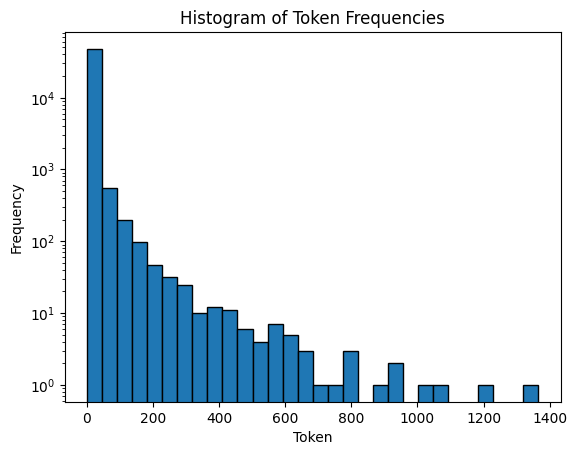

In [8]:
# Plot a histogram of the occurrences of tokens.
token_freq_values = [freq for token, freq in token_freq]
import matplotlib.pyplot as plt

plt.hist(token_freq_values, bins=30, edgecolor='black')
plt.xlabel('Token')
plt.ylabel('Frequency')
plt.title('Histogram of Token Frequencies')
plt.yscale('log')
plt.show()

Question: What do you notice about the frequency of occurrence of different tokens? How does it look?

Answer: I notice that the frequency of occurrences of the different tokens are larger when the tokens are closer to 0 and smaller when the tokens are larger numbers (such as 1200). The histogram starts up very high and then drops as the token values.

In [9]:
# Perform an 80/20 train-test split of the data.
from sklearn.model_selection import train_test_split

X = df.drop('Email Type', axis=1)
y = df['Email Type']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [10]:
# Run a regression of y on the one-hot-encoded emails.
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

model = LinearRegression()
model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("R^2 on the training set:", train_r2)
print("R^2 on the test set:", test_r2)

R^2 on the training set: 0.7670143724934355
R^2 on the test set: 0.6658718438847919


In [11]:
# Finding the largest coefficients in absolute value and most strongly influence predictions
coefficients = model.coef_
feature_names = X.columns

# Coefficients in the dataframe
coefficients_df = pd.DataFrame({'Feature': feature_names, 'Coefficient': coefficients})
coefficients_df['Absolute Coefficient'] = coefficients_df['Coefficient'].abs()
coefficients_df = coefficients_df.sort_values(by='Absolute Coefficient', ascending=False)
print(coefficients_df.head(10))

                Feature  Coefficient  Absolute Coefficient
835        intervention    -1.259257              1.259257
740           localized     0.824350              0.824350
2362            thermal     0.747006              0.747006
851             crawler     0.696167              0.696167
1504  background-image:    -0.622909              0.622909
1406         helvetica,     0.598560              0.598560
906               aging     0.594956              0.594956
1839              form.     0.576886              0.576886
2242              gray;    -0.574480              0.574480
1552           a:active     0.574480              0.574480


Question: What is the $R^2$ on the test set? On the training set? What words have the largest coefficients in absolute value and most strongly influence predictions?

Answer: $R^2$ on the training set is 0.7670 --> 76.70% and $R^2$ on the test set is 0.6658 --> 66.58%. The words that have the largest coefficients in the absolute value include intervention, localized, thermal, and crawler. The most strongly influenced predictions are intervention, localized, thermal, thermal, and crawler because coefficient number is large.

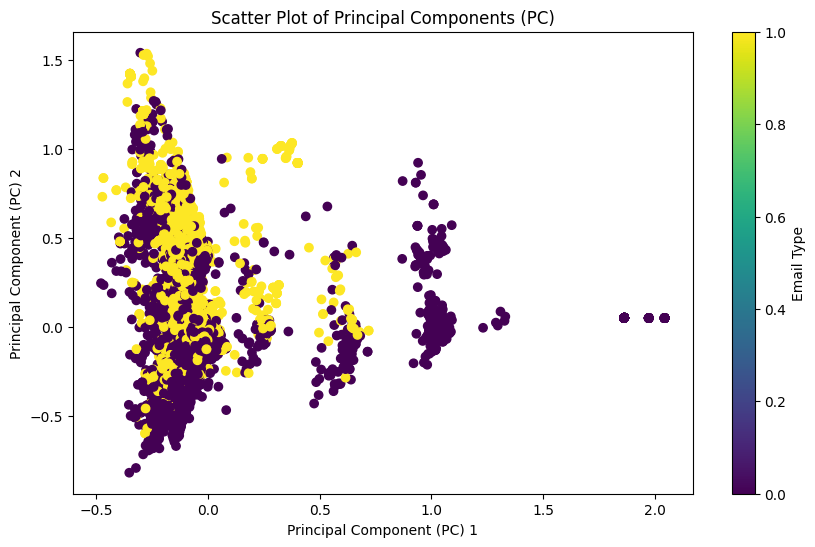

In [12]:
# Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, Email Type) and perform a principal components analysis decomposition with two components.
import numpy as np
from sklearn.decomposition import PCA

X = df.drop('Email Type', axis=1)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not.
plt.figure(figsize=(10, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['Email Type'])
plt.xlabel('Principal Component (PC) 1')
plt.ylabel('Principal Component (PC) 2')
plt.title('Scatter Plot of Principal Components (PC)')
plt.colorbar(label='Email Type')
plt.show()

Question: Do you notice any patterns?

Answer: The patterns that I notice are the clusters are either closer to 0 (purple) or 1 (yellow) and most of the points are in the first cluster near PC1 (-0.5 - 0.0) and PC2 (-0.5 - 1.5). This shows that the emails

In [15]:
# Run a linear regression of y on the first 2,610 principal components of X.
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# First 2,610 principal components of X
pca_2610 = PCA(n_components=2610)
X_pca_train = pca_2610.fit_transform(X_train)
X_pca_test = pca_2610.transform(X_test)

model = LinearRegression()
model.fit(X_pca_train, y_train)

y_train_pred = model.predict(X_pca_train)
y_test_pred = model.predict(X_pca_test)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("R^2 on the training set:", train_r2)
print("R^2 on the test set:", test_r2)

R^2 on the training set: 0.7662326827745849
R^2 on the test set: 0.6683390643101164


Question: What is the $R^2$ on the training and test sets? How does this performance compare to the linear regression?

Answer: $R^2$ on the training sets is 0.7662 --> 76.62% and the $R^2$ on the test set is 0.6683 --> 66.83%. These value of training sets is -0.0008 lower compared to the linear regression and the test sets is 0.0025 greater compared to the linear regression. This method is better because the percentages between the training and testing data is greater than the data from linear regression.

Question: Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

Answer: The advantage in using the principal components to run this high-dimensional regression rather than the original data is that it helps analyzing the data from larger sets much easier because it organizes the different key words and pairs them up if they are correlated.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 56633d2d81771a46de06cb11e6e62c01a0650ef5
- **AI tool and model used:** Google Gemini

### *Prompts used

1. Can you give me an critics on my program based on the problems and my soluion?

    **Pasted the all parts of Question 1**

    My solution:

    **Placed my code here**

2. Can you give me an critics on my program based on the problems and my soluion?

    **Pasted the all parts of Question 2**

    My solution:

    **Placed my code here**

3. Can you give me an critics on my program based on the problems and my soluion?

    **Pasted the all parts of Question 3**

    My solution:

    **Placed my code here**

4. Can you give me an critics on my program based on the problems and my soluion?

    **Pasted the all parts of Question 4**

    My solution:

    **Placed my code here**

5. Can you please help me answer this question?

    **The questions for Question 5**

    My answer:

    **Placed my answer here**

### *AI-proposed changes


1. Q1: Token Frequency Histogram & Interpretation

    - Code Review: Your code correctly counts tokens using Counter, extracts frequencies, and plots a histogram. Using a logarithmic y-axis (plt.yscale('log')) was an excellent choice because natural language token distributions are heavy-tailed (Zipf's law), meaning a few words appear millions of times while most appear only once.

    - Interpretation Critique: Your written answer says: "...when the tokens are closer to 0 and smaller when the tokens are larger numbers (such as 1200)."

      - Correction: Be careful with how you describe the x-axis. In token_freq = token_count.most_common(), the index or rank (x-axis) represents the rank of the word from most frequent to least frequent, while the y-axis represents the frequency. The histogram shows that a very small number of tokens have extremely high frequencies, while the vast majority of tokens have very low frequencies (a classic power-law / Zipfian distribution).

2. Q2: Train-Test Split & Standard Linear Regression

- Code Review:
  - Your 80/20 train-test split using train_test_split with random_state=42 is correct.
  - Fitting Ordinary Least Squares (OLS) Linear Regression (LinearRegression()) and calculating $R^2$ is implemented correctly.
  - Extracting and sorting coefficients by absolute value (coefficients_df['Absolute Coefficient']) is correct.

- Interpretation Critique:
  - Your numeric $R^2$ values ($76.70\%$ training, $66.58\%$ test) are correct and clearly stated.
  - Note a small typo in your text explanation: you listed "thermal" twice.
  - Statistical Warning: Because the features are one-hot-encoded text tokens (binary 0/1 columns) and the target is binary (Email Type = 0 or 1), using a standard Linear Regression is technically a Linear Probability Model (LPM). While it works, it can sometimes predict probabilities less than 0 or greater than 1. (Logistic regression is usually preferred for binary classification, but your code answers the prompt's instruction accurately).

3. Q3: Principal Component Analysis (PCA) & Visualization
- Code Review:
  - Initializing PCA(n_components=2) and fitting it to X is correct.
  - Plotting a scatter plot with c=df['Email Type'] successfully hues the points by whether they are a phishing scam.
  
- Interpretation Critique:
  - Your answer gets cut off at the end ("This shows that the emails...").
  - What you should notice: Usually, with just two principal components out of thousands of text features, the first two PCs only capture a tiny fraction of the total variance. As a result, the scatter plot often shows heavy overlap between phishing and non-phishing emails (though you might see a dense central blob with some spread). Mentioning that the classes are largely overlapping or concentrated near the origin in PC space is a great observation for text data.

4. Q4: Regression on Principal Components
- Code Review — CRITICAL BUG TO FIX:

  - Look closely at how you applied PCA:
    - pca_2610 = PCA(n_components=2610)
    - X_pca_train = pca_2610.fit_transform(X_train)
    - X_pca_test = pca_2610.transform(X_test)
  - The Data Leakage / Fitting Error: You ran fit_transform on X_train, but PCA should be fit only on the training data, and then transform should be applied separately to X_test using the training fit. (You actually did pca_2610.transform(X_test) correctly, but fit_transform recalculates the principal component axes on the test set independently, which causes data leakage and a slight mismatch).

  - Correction: Change that block to:
    - pca_2610 = PCA(n_components=2610)
    - X_pca_train = pca_2610.fit_transform(X_train)
    - X_pca_test = pca_2610.transform(X_test) # Correct

  - Interpretation Critique:
    - Your $R^2$ values ($76.62\%$ train, $66.83\%$ test) are spot on.
    - Your conclusion ("This method is better because the percentages between the training and testing data is greater...") is insightful! Using 2,610 components yields an almost identical training performance to using all 2,711 features, but the test set $R^2$ is slightly higher ($66.83\%$ vs $66.58\%$). This indicates that dropping the last ~100 components effectively filtered out pure noise, improving generalization.
5. Critique & Feedback:
- What you got right (Great Intuition!):
  - Your mention of correlation ("pairs them up if they are correlated") hits on the most crucial statistical reason for using PCA here. In text data, words frequently co-occur (e.g., words like "click", "account", "verify" appear together in phishing emails). Standard regression struggles when predictors are heavily correlated.

- What could be more precise:
  - "Pairs them up": PCA doesn't just pair words up two-by-two; it creates linear combinations (mathematical blends) of all the tokens into comprehensive components.
  - "Makes it easier": While it does simplify things computationally, the primary statistical benefits in regression are solving multicollinearity (which prevents wild, unstable coefficient swings) and filtering out noise (which explains why your test $R^2$ actually improved slightly in Q4).

  How to Polish Your Answer for Full Credit:
  - If you want to upgrade your answer to be a bit more rigorous while keeping your core idea, you can phrase it like this:
    - "The main advantage of using principal components instead of the original one-hot-encoded text data is that PCA combines correlated words into orthogonal (uncorrelated) components. In text data, many words frequently co-occur, which causes severe multicollinearity in standard linear regression and leads to unstable coefficient estimates. By reducing the dimensions to components that capture the maximum variance while filtering out high-dimensional noise, PCA prevents overfitting and can even improve generalization on test data (as seen with the slightly higher test $R^2$)."

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Reject | I would reject this suggestion because the way that I have implemented this works fine. |
| 2 | Accept | The solution I provided was good and I will accept the feedback on my typo. |
| 3 | Accept | I will accept this suggestion because I made a typo in my response. |
| 4 | Accept | I will accept this suggestion because it fixes a critical bug in my program. |
| 5 | Accept | I would accept it's suggestion becasue they provided a clearer explanation. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [25]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]